# 5. Афтершоки: закон Омори–Уцу

После сильного землетрясения частота повторных толчков убывает со временем по закону
Омори (1894) в форме Уцу (1961):

$$n(t) = \frac{K}{(t + c)^p}$$

- **p** — скорость затухания (обычно 0.9–1.5);
- **c** — небольшая задержка, сглаживающая особенность при t → 0;
- **K** — продуктивность последовательности.

Для служб ЧС этот закон практически важен: он даёт ожидаемое число опасных афтершоков
в ближайшие сутки и недели, когда идут спасательные работы в повреждённых зданиях.

**Метод.**
1. Афтершоки отбираются в окне вокруг главного толчка: радиус — максимум из окна
   Гарднера–Кнопова (1974) и длины разрыва по Wells & Coppersmith (1994), 365 суток, M ≥ 5.0.
2. Параметры оцениваются **методом максимального правдоподобия** для неоднородного пуассоновского
   процесса (Ogata, 1983). При фиксированных (c, p) оптимальное K выражается аналитически,
   поэтому функция правдоподобия считается сразу на всей сетке (c, p) через broadcasting NumPy.
3. Неопределённость p — бутстрэп (200 повторов).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from seismic import analysis, plots, stats

plots.setup_style()
pd.set_option("display.width", 160)

events = analysis.load_events()
omori, sequences = analysis.omori_table(events, days=365, t_start=0.05)
omori.round(3)

,event,mag,radius_km,days,n_aftershocks,max_aftershock,bath_delta,K,c_days,p,p_lo,p_hi
0,"Суматра, 2004 (M9.1)",9.1,849.180,365.000,677,8.6,0.5,45.387,0.001,0.77,0.74,0.800
1,"Чили, 2010 (M8.8)",8.8,564.937,365.000,402,7.4,1.4,42.508,0.012,0.98,0.94,1.090
2,"Тохоку, 2011 (M9.1)",9.1,849.180,365.000,798,7.9,1.2,97.074,0.047,1.03,0.99,1.060
3,"Непал, 2015 (M7.8)",7.8,145.211,365.000,28,7.3,0.5,1.858,0.001,0.98,0.81,1.271
4,"Турция, 2023 (M7.8)",7.8,145.211,365.000,29,7.5,0.3,11.582,0.622,1.68,1.32,2.500
5,"Камчатка, 2025 (M8.8)",8.8,564.937,154.986,429,7.8,1.0,42.030,0.001,0.89,0.84,0.930


## 5.1. Затухание афтершоков

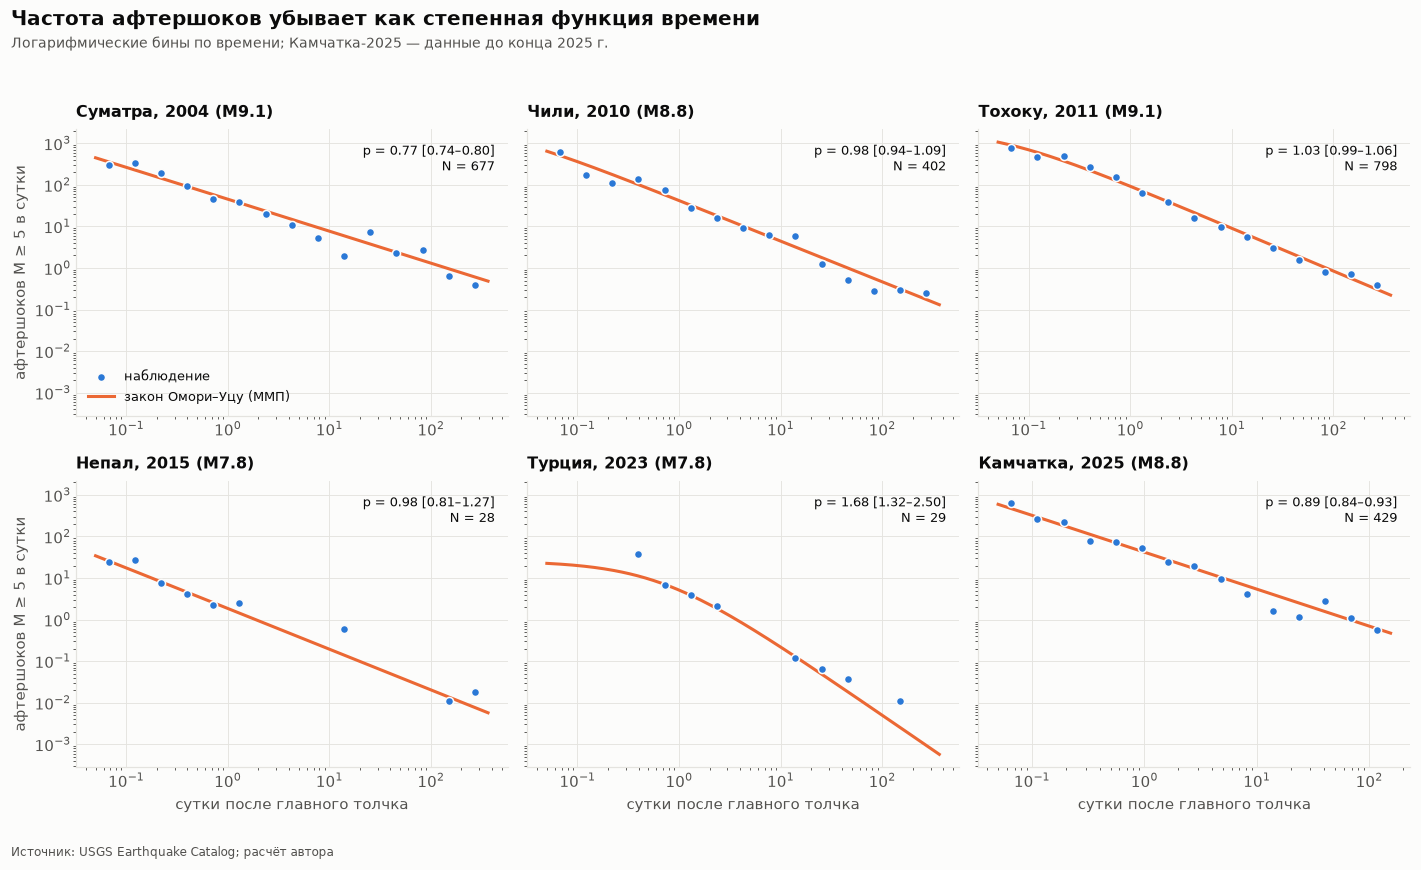

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.6), sharey=True)
for ax, (label, (main, after, fit)) in zip(axes.flat, sequences.items()):
    t = after["t_days"].to_numpy()
    edges = np.logspace(np.log10(0.05), np.log10(fit["t_end"]), 16)
    counts, _ = np.histogram(t, bins=edges)
    centers = np.sqrt(edges[:-1] * edges[1:])     # геометрический центр бина
    rate = counts / np.diff(edges)                 # событий в сутки
    ok = counts > 0
    ax.scatter(centers[ok], rate[ok], s=28, color=plots.SERIES[0], zorder=3,
               edgecolors=plots.SURFACE, linewidths=1, label="наблюдение")
    grid = np.logspace(np.log10(0.05), np.log10(fit["t_end"]), 200)
    ax.plot(grid, stats.omori_rate(grid, fit["K"], fit["c"], fit["p"]), color=plots.SERIES[1],
            label="закон Омори–Уцу (ММП)")
    row = omori.set_index("event").loc[label]
    ax.text(0.97, 0.95, f"p = {row['p']:.2f} [{row['p_lo']:.2f}–{row['p_hi']:.2f}]\nN = {row['n_aftershocks']:.0f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=plots.TEXT)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(axis="x", visible=True)
    ax.set_title(label, fontsize=10.5, pad=8)
for ax in axes[1]:
    ax.set_xlabel("сутки после главного толчка")
for ax in axes[:, 0]:
    ax.set_ylabel("афтершоков M ≥ 5 в сутки")
axes[0, 0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Частота афтершоков убывает как степенная функция времени", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, 0.935, "Логарифмические бины по времени; Камчатка-2025 — данные до конца 2025 г.",
         fontsize=9, color=plots.TEXT_MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plots.source_note(fig, "Источник: USGS Earthquake Catalog; расчёт автора")
plots.save(fig, "14_omori_aftershocks")
plt.show()

Для четырёх из шести последовательностей p лежит в интервале 0.8–1.05 — типичные значения
для зон субдукции. Отклонения объяснимы:

- **Суматра-2004** (p ≈ 0.77): через три месяца в том же окне произошло землетрясение Ниас M8.6 —
  по сути, отдельное событие со своей последовательностью, которое «подпитывает» хвост.
- **Турция-2023** (p ≈ 1.7): «дуплет» — через 9 часов после M7.8 произошёл толчок M7.5, и
  основная масса афтершоков сосредоточена в первые сутки; к тому же выборка мала (N ≈ 30).

## 5.2. Прикладная оценка: сколько ждать сильных афтершоков

Интегрируя n(t), получаем ожидаемое число афтершоков M ≥ 5 в любом интервале. Это та оценка,
которую сейсмологические службы публикуют после крупных землетрясений.

In [3]:
def expected_count(fit: dict, t1: float, t2: float) -> float:
    return fit["K"] * float(stats._omori_integral(np.array(fit["c"]), np.array(fit["p"]), t1, t2))


windows = {"сутки 1–2": (1, 2), "дни 2–7": (2, 7), "дни 7–30": (7, 30), "дни 30–365": (30, 365)}
forecast = pd.DataFrame({
    label: {name: expected_count(fit, *w) for name, w in windows.items() if w[1] <= fit["t_end"]}
    for label, (_, _, fit) in sequences.items()
}).T.round(1)
observed = pd.DataFrame({
    label: {name: int(((after["t_days"] > w[0]) & (after["t_days"] <= w[1])).sum())
            for name, w in windows.items() if w[1] <= fit["t_end"]}
    for label, (_, after, fit) in sequences.items()
}).T
pd.concat({"прогноз по модели": forecast, "факт": observed}, axis=1)

прогноз по модели                                  факт                            
                              сутки 1–2 дни 2–7 дни 7–30 дни 30–365 сутки 1–2 дни 2–7 дни 7–30 дни 30–365
Суматра, 2004 (M9.1)               34.1    77.3    122.7      335.1      38.0    57.0     42.0      422.0
Чили, 2010 (M8.8)                  29.4    54.5     65.2      116.6      28.0    50.0     84.0      100.0
Тохоку, 2011 (M9.1)                64.3   115.3    129.9      210.9      66.0    98.0     99.0      232.0
Непал, 2015 (M7.8)                  1.3     2.4      2.9        5.1       2.0     0.0      5.0        4.0
Турция, 2023 (M7.8)                 3.4     4.6      2.6        1.4       3.0     3.0      2.0        2.0
Камчатка, 2025 (M8.8)              30.3    60.9     82.2        NaN      25.0    61.0     39.0        NaN

## 5.3. Закон Бота

Эмпирический закон Бота (Båth, 1965): сильнейший афтершок в среднем на ~1.2 единицы магнитуды
слабее главного толчка.

In [4]:
bath = omori[["event", "mag", "max_aftershock", "bath_delta"]].rename(columns={
    "mag": "главный толчок", "max_aftershock": "сильнейший афтершок", "bath_delta": "ΔM"})
print(f"Медиана ΔM = {bath['ΔM'].median():.2f}")
bath

Медиана ΔM = 0.75


,event,главный толчок,сильнейший афтершок,ΔM
0,"Суматра, 2004 (M9.1)",9.1,8.6,0.5
1,"Чили, 2010 (M8.8)",8.8,7.4,1.4
2,"Тохоку, 2011 (M9.1)",9.1,7.9,1.2
3,"Непал, 2015 (M7.8)",7.8,7.3,0.5
4,"Турция, 2023 (M7.8)",7.8,7.5,0.3
5,"Камчатка, 2025 (M8.8)",8.8,7.8,1.0


Для Чили, Тохоку и Камчатки ΔM = 1.0–1.4 — в согласии с законом Бота. В трёх других случаях
ΔM ≈ 0.3–0.5: «афтершок» там — крупное самостоятельное событие (Ниас-2005 M8.6, толчок
12 мая 2015 г. M7.3 в Непале, второй толчок M7.5 в Турции). Для служб ЧС это важный урок:
закон Бота описывает среднее, и сопоставимый по силе повторный удар исключать нельзя.

**Выводы ноутбука:**
1. Затухание афтершоков всех шести крупнейших последовательностей описывается законом Омори–Уцу.
2. Типичный показатель p ≈ 0.9–1.0: при таком затухании частота афтершоков через неделю в ~7 раз
   ниже, чем в первые сутки, поэтому первые дни наиболее опасны для спасательных работ.
3. Для «одиночных» последовательностей (Чили, Тохоку) модель воспроизводит число афтершоков по
   интервалам с точностью ~20–30%. Там, где возникает второе крупное событие (Суматра → Ниас),
   простая модель Омори недостаточна — нужны модели эпидемического типа (ETAS).